# 03 — 2D CNN over a weekly grid (Junzhe Xu, Lab 6)

**Question:** if one week of hourly data is laid out as an image, can
convolution filters learn useful local patterns?

**Why a CNN:** a filter slides over the grid with shared weights, so it can
learn a shape such as "quiet early morning, then a sharp commute rise"
wherever it appears.

**Input:** the same 168-hour window as the LSTM, reshaped to
`23 channels × 7 days × 24 hours`. The prediction hour is always the
bottom-right cell.

| Section | What it shows |
|---|---|
| 1 | Load data and build the weekly images |
| 2 | The CNN model |
| 3 | Architecture ablation (depth, kernel size) |
| 4 | Final CNN and training curves |
| 5 | Validation / test results, diagnostics, feature maps |
| 6 | Cost and saved evidence |
| 7 | Conclusion |

## 1. Setup and weekly images
Training uses the same shared loop as the LSTM (`bc.train_regressor`), so the
two deep models are compared under the same regime.

**Data pipeline at a glance** (what `bike_common` does before any model sees the data):

1. reads `hour.csv` and rebuilds a complete hourly calendar — the 165 missing hours are added back;
2. forward-fills weather and past demand from earlier hours only; `cnt` stays empty at missing hours, so it is never a target;
3. builds the 23 shared features: one-hot season and weather, sin/cos month, hour and weekday, holiday and working-day flags, four weather values, and `lag1`, `lag24`, `lag168`, `roll24`, `roll168`;
4. assigns the frozen split (train → 2012-05-25, validation → 2012-09-12, test → 2012-12-31) and drops the two-week warm-up;
5. fits the scaler on training rows only.

`prepare_tabular()` returns one row per hour; `prepare_sequences(window)` returns the same rows as sliding windows.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

for p in [Path.cwd(), *Path.cwd().parents]:            # locate the shared module
    hits = [q for q in (p, p / "src", p / "code" / "src") if (q / "bike_common.py").exists()]
    if hits:
        sys.path.insert(0, str(hits[0]))
        break
import bike_common as bc

bc.setup_plot_style()
SEED = bc.SEED
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
d = bc.prepare_tabular()

seq = bc.prepare_sequences(window=168)
X = {n: bc.reshape_weekly(seq[n]["X"]).astype(np.float32) for n in ("train", "validation", "test")}
y = {n: seq[n]["y"] for n in ("train", "validation", "test")}
y_mean, y_std = float(y["train"].mean()), float(y["train"].std())
print("Image tensor:", X["train"].shape, "(samples, channels, 7 days, 24 hours)")

Image tensor: (11816, 23, 7, 24) (samples, channels, 7 days, 24 hours)


## 2. Model
Conv → BatchNorm → ReLU blocks, max-pool, global average pool. The head also
receives the **prediction hour's own 23 features** (bottom-right cell), so
pooling does not dilute the current weather and calendar values.

In [2]:
class CNNRegressor(nn.Module):
    def __init__(self, input_channels, channels=(32, 64), kernel_size=3, dropout=0.2):
        super().__init__()
        layers, in_ch = [], input_channels
        for out_ch in channels:
            layers += [nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size // 2),
                       nn.BatchNorm2d(out_ch), nn.ReLU()]
            in_ch = out_ch
        layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Linear(in_ch + input_channels, 32), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, x):
        spatial = self.pool(self.features(x)).flatten(1)
        current = x[:, :, -1, -1]                       # prediction-hour features
        return self.head(torch.cat([spatial, current], dim=1))


def run_cnn(channels, kernel_size, max_epochs=15, patience=4, tag="cnn"):
    return bc.train_regressor(
        lambda: CNNRegressor(X["train"].shape[1], channels, kernel_size, 0.2),
        X["train"], y["train"], X["validation"], y["validation"], y_mean, y_std,
        max_epochs=max_epochs, patience=patience, tag=tag)

## 3. Architecture ablation
| Name | Conv layers | Kernel | Channels |
|---|---|---|---|
| `shallow_k3` | 1 | 3×3 | 32 |
| `base_k3` | 2 | 3×3 | 32 → 64 |
| `base_k5` | 2 | 5×5 | 32 → 64 |

Each run: ≤15 epochs, early stopping, compared on validation MAE.

shallow_k3 epoch 01  train 0.3080  val 0.2724  val MAE 68.57


shallow_k3 epoch 02  train 0.1475  val 0.2317  val MAE 59.49


shallow_k3 epoch 03  train 0.1267  val 0.2009  val MAE 54.45


shallow_k3 epoch 04  train 0.1167  val 0.1873  val MAE 52.03


shallow_k3 epoch 05  train 0.1097  val 0.2020  val MAE 54.58


...

base_k5 epoch 09  train 0.0717  val 0.1222  val MAE 40.77


base_k5 epoch 10  train 0.0693  val 0.1688  val MAE 49.73


base_k5 epoch 11  train 0.0668  val 0.1146  val MAE 38.70


base_k5 epoch 12  train 0.0627  val 0.1290  val MAE 41.76


base_k5: early stop at epoch 12 (best epoch 8, MAE 38.73)


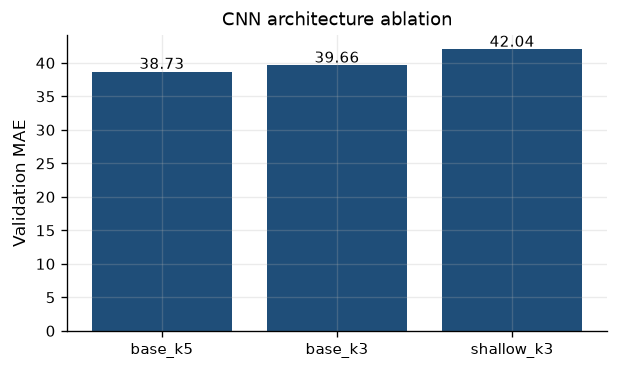

Selected architecture: {'name': 'base_k5', 'channels': (32, 64), 'kernel_size': 5}


,config,channels,kernel,best_epoch,val_MAE,train_seconds,params
0,base_k5,"(32, 64)",5,8,38.728,82.029,72737
1,base_k3,"(32, 64)",3,15,39.657,81.467,28193
2,shallow_k3,"(32,)",3,14,42.038,31.799,8545


In [3]:
configs = [{"name": "shallow_k3", "channels": (32,), "kernel_size": 3},
           {"name": "base_k3", "channels": (32, 64), "kernel_size": 3},
           {"name": "base_k5", "channels": (32, 64), "kernel_size": 5}]
ablation = []
for cfg in configs:
    run = run_cnn(cfg["channels"], cfg["kernel_size"], tag=cfg["name"])
    ablation.append({"config": cfg["name"], "channels": str(cfg["channels"]),
                     "kernel": cfg["kernel_size"], "best_epoch": run["best_epoch"],
                     "val_MAE": run["best_val_MAE"], "train_seconds": run["train_seconds"],
                     "params": sum(p.numel() for p in run["model"].parameters())})
ablation = pd.DataFrame(ablation).sort_values("val_MAE").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(5.8, 3.2))
ax.bar(ablation["config"], ablation["val_MAE"], color="#1f4e79")
for i, v in enumerate(ablation["val_MAE"]):
    ax.text(i, v + 0.4, f"{v:.2f}", ha="center", fontsize=9)
ax.set(title="CNN architecture ablation", ylabel="Validation MAE")
bc.save_figure(fig, "fig_cnn_ablation.png")
plt.show()

best_config = next(c for c in configs if c["name"] == ablation.iloc[0]["config"])
print("Selected architecture:", best_config)
ablation.round(3)

## 4. Final CNN
Selected architecture retrained with a larger budget (≤50 epochs, patience 7).

final epoch 01  train 0.2305  val 0.2311  val MAE 61.91


final epoch 02  train 0.1290  val 0.2286  val MAE 61.53


final epoch 03  train 0.1124  val 0.1597  val MAE 47.08


final epoch 04  train 0.0992  val 0.1480  val MAE 45.03


final epoch 05  train 0.0879  val 0.1476  val MAE 46.71


...

final epoch 22  train 0.0508  val 0.1014  val MAE 35.59


final epoch 23  train 0.0488  val 0.0975  val MAE 34.76


final epoch 24  train 0.0489  val 0.1019  val MAE 35.58


final epoch 25  train 0.0489  val 0.1108  val MAE 37.35


final: early stop at epoch 25 (best epoch 18, MAE 33.51)
Best epoch 18 | validation MAE 33.51 | 253 s


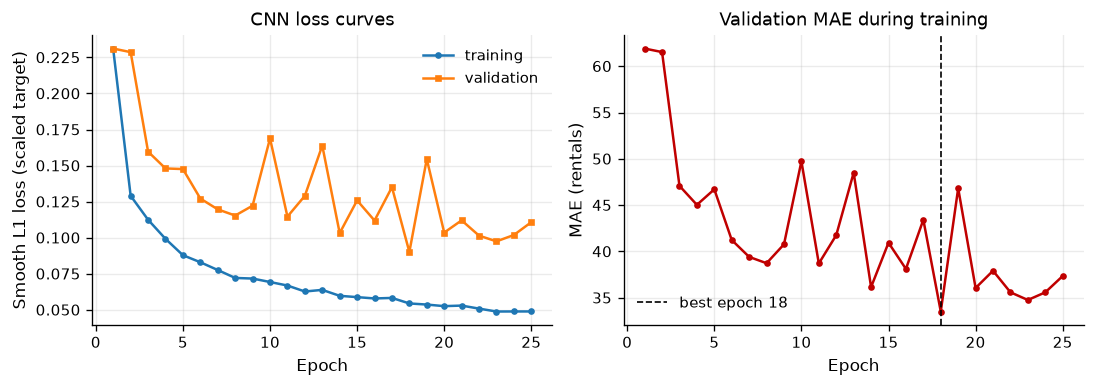

In [4]:
final_run = run_cnn(best_config["channels"], best_config["kernel_size"],
                    max_epochs=50, patience=7, tag="final")
final_model = final_run["model"]
print(f"Best epoch {final_run['best_epoch']} | validation MAE {final_run['best_val_MAE']:.2f} "
      f"| {final_run['train_seconds']:.0f} s")
bc.plot_training_curves(final_run["history"], final_run["best_epoch"], "CNN",
                        "fig_cnn_training_curves.png")

## 5. Results

In [5]:
val_pred = bc.predict_regressor(final_model, X["validation"], y_mean, y_std)
test_pred = bc.predict_regressor(final_model, X["test"], y_mean, y_std)
ev = bc.evaluate(y["validation"], val_pred, y["test"], test_pred,
                 d["validation"], d["test"], d["train"])
bc.scenario_table(ev)

Validation: MAE 33.51 | RMSE 49.84 | R2 0.9503
Test:       MAE 31.56 | RMSE 48.04 | R2 0.9497


,validation n,validation MAE,test n,test MAE
peak_hours,660,53.54,653,49.46
off_peak_hours,1980,26.84,1947,25.56
weekday,1800,31.83,1737,31.63
weekend_or_holiday,840,37.13,863,31.42
high_demand,1381,44.72,1055,44.56
lower_demand,1259,21.22,1545,22.68


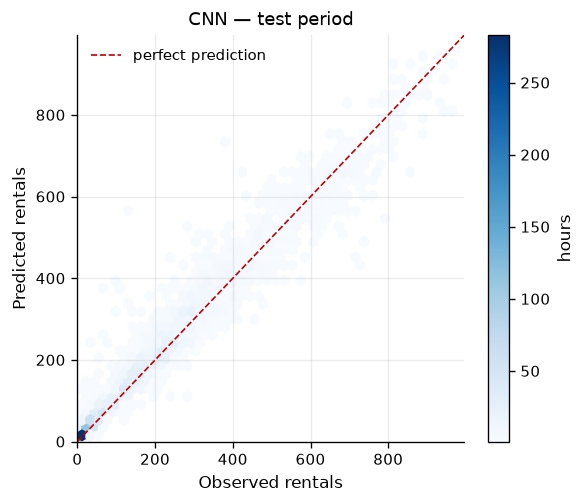

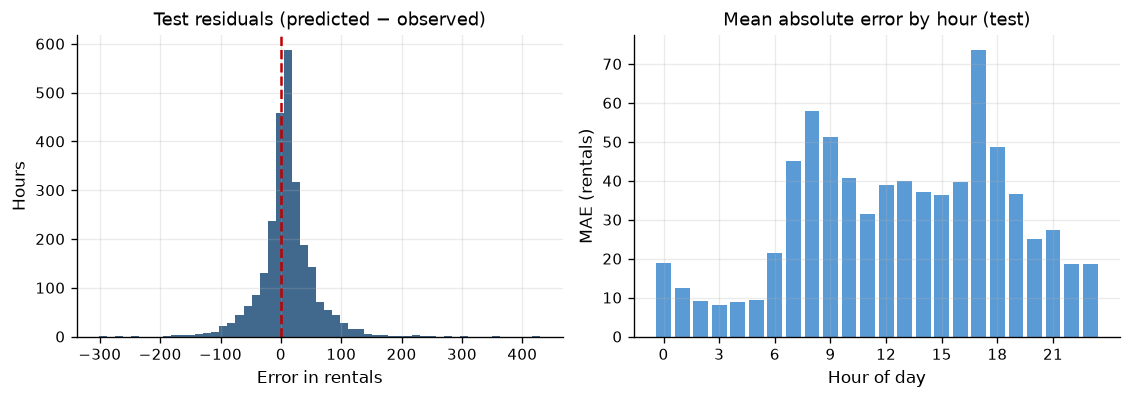

Residual mean 10.03 | standard deviation 46.98


/home/peterhanhhh/IntroToAI/AI project/project/src/bike_common.py:718: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  return frame.loc[frame["error"].abs().sort_values(ascending=False).index[:n], cols].round(1)


,dteday,hr,weekday,workingday,weathersit,temp,hum,cnt,prediction,error
464,2012-10-02,8,2,1,3,0.6,0.9,134,564.099976,430.1
1636,2012-11-21,17,3,1,1,0.4,0.4,374,731.700012,357.7
2417,2012-12-24,8,1,1,1,0.2,0.7,66,373.799988,307.8
1675,2012-11-23,8,5,1,1,0.2,0.9,94,401.100006,307.1
1842,2012-11-30,8,5,1,2,0.2,0.8,729,427.799988,-301.2
1660,2012-11-22,17,4,0,1,0.4,0.4,109,382.399994,273.4
632,2012-10-09,8,2,1,2,0.4,0.8,713,448.500000,-264.5
691,2012-10-11,19,4,1,1,0.4,0.5,743,481.200012,-261.8
138,2012-09-18,18,2,1,2,0.6,0.9,281,526.400024,245.4
64,2012-09-15,16,6,0,2,0.7,0.4,783,544.700012,-238.3


In [6]:
bc.plot_diagnostics(y["test"], test_pred, d["test"]["hr"], "CNN", "cnn")
bc.worst_errors(d["test"], test_pred)

### What the first convolution layer responds to
Activation maps of the first 8 filters for one validation week: bright cells
show where a filter fires, i.e. the network uses local structure.

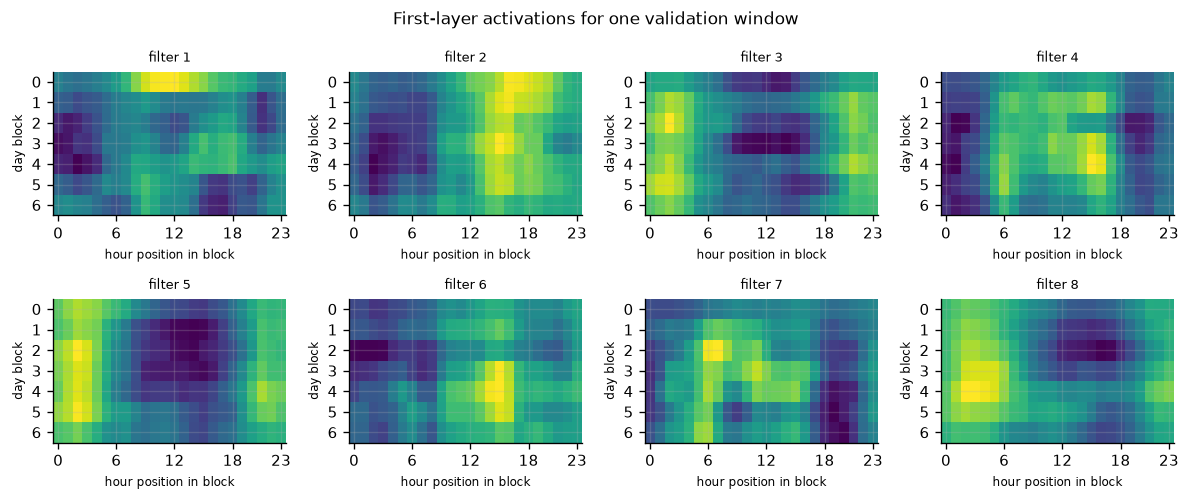

In [7]:
with torch.no_grad():
    maps = final_model.features[0](torch.tensor(X["validation"][:1]))[0].numpy()
fig, axes = plt.subplots(2, 4, figsize=(10, 4.2))
for ch, ax in enumerate(axes.ravel()):
    ax.imshow(maps[ch], cmap="viridis", aspect="auto")
    ax.set_title(f"filter {ch + 1}", fontsize=8)
    ax.set_xticks([0, 6, 12, 18, 23])
    ax.set_yticks(range(7))
    ax.set_xlabel("hour position in block", fontsize=7)
    ax.set_ylabel("day block", fontsize=7)
plt.suptitle("First-layer activations for one validation window", fontsize=10)
plt.tight_layout()
bc.save_figure(fig, "fig_cnn_feature_maps.png")
plt.show()

## 6. Cost and saved evidence

In [8]:
model_path = bc.MODELS_DIR / "cnn_model.pt"
torch.save(final_model.state_dict(), model_path)
latency = bc.measure_inference(lambda Z: bc.predict_regressor(final_model, Z, y_mean, y_std),
                               X["test"], repeats=3)
print(f"Model {bc.file_mb(model_path):.2f} MB | single row {latency['single_row_ms']:.2f} ms")

bc.save_predictions(d["test"], test_pred, "pred_cnn_test.csv")
bc.save_predictions(d["validation"], val_pred, "pred_cnn_validation.csv")
config = {"window": 168, "input_channels": int(X["train"].shape[1]),
          "channels": list(best_config["channels"]), "kernel_size": best_config["kernel_size"],
          "dropout": 0.2, "target_mean": y_mean, "target_std": y_std,
          "features": d["feature_names"], "seed": SEED}
bc.save_json(config, "cnn_config.json")
bc.save_json({
    "method": "2D CNN", "owner": "Junzhe Xu", "lab": "Lab 6", "config": config,
    "architecture_ablation": ablation.to_dict(orient="records"),
    "best_epoch": int(final_run["best_epoch"]), **ev,
    "train_seconds": float(final_run["train_seconds"]),
    "model_size_mb": bc.file_mb(model_path), "inference": latency,
    "train_rows": int(len(y["train"])),
    "history": final_run["history"].to_dict(orient="records"),
}, "cnn_metrics.json")
print("Saved results/cnn_metrics.json, prediction CSVs and models/cnn_model.pt")

Model 0.28 MB | single row 4.20 ms
Saved results/cnn_metrics.json, prediction CSVs and models/cnn_model.pt


## 7. Conclusion
* Laying the week out as a 7×24 image works: the CNN is a close second to
  the LSTM on validation MAE.
* The ablation shows how depth and kernel size change the result.
* It is small on disk and fast per prediction; notebook 05 weighs this.